[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/08_positional_encoding.ipynb)

# 08 · Positional Encoding: Telling Attention About Order

*Attention, Explained · Hamza Hentabli, Ph.D. · ~25 min*

Attention compares every word with every other word — but it has no idea **which came first**. In this notebook we prove that with an experiment, then fix it with the sinusoidal **positional encoding** from *Attention Is All You Need*, plot it, verify its key properties numerically, and meet its modern successor, RoPE.

**Learning objectives.** By the end of this notebook you will be able to:

- show experimentally that self-attention is **permutation-equivariant**
- compute and plot **sinusoidal positional encodings**
- verify that nearby positions are similar and that a **shift is a rotation**
- compare learned, relative, **RoPE** and ALiBi position schemes

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. Attention is blind to order — a proof by experiment

Look at the attention formula again: every query is compared with every key, and the weighted sum does not care in which order the keys are listed. So if we shuffle the input tokens, self-attention just shuffles its outputs the same way. **"dog bites man"** and **"man bites dog"** produce the *same three vectors*, only reordered.

In [2]:
vocab, w2i, E = au.cooccurrence_embeddings(dim=16)
rng = np.random.default_rng(0)
d = E.shape[1]
WQ, WK, WV = (rng.normal(scale=d ** -0.5, size=(d, d)) for _ in range(3))
attend = lambda X: au.scaled_dot_product_attention(X @ WQ, X @ WK, X @ WV)[0]

s1, s2 = ["dog", "chases", "cat"], ["cat", "chases", "dog"]
Z1 = attend(E[[w2i[w] for w in s1]])
Z2 = attend(E[[w2i[w] for w in s2]])
for w in s1:
    same = np.allclose(Z1[s1.index(w)], Z2[s2.index(w)])
    print(f"output vector for '{w}' identical in both sentences: {same}")

output vector for 'dog' identical in both sentences: True
output vector for 'chases' identical in both sentences: True
output vector for 'cat' identical in both sentences: True


Self-attention is **permutation-equivariant**: it treats a sentence as a *bag* of words. Recurrent networks got order for free by reading left to right; attention looks at everything at once, so we must **inject position information** into the vectors themselves.

## 2. Sinusoidal positional encoding

The original Transformer (Vaswani et al., 2017) adds a fixed vector $PE_{pos}$ to each token embedding:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

Each pair of dimensions is a sine/cosine **clock** ticking at its own speed: the first dimensions spin fast (they distinguish neighbouring positions), the last ones spin very slowly (they tell the start of a long document from the end). It is like reading a time from a second hand, a minute hand and an hour hand together.

PE shape: (100, 64) | values in -1.0 to 1.0


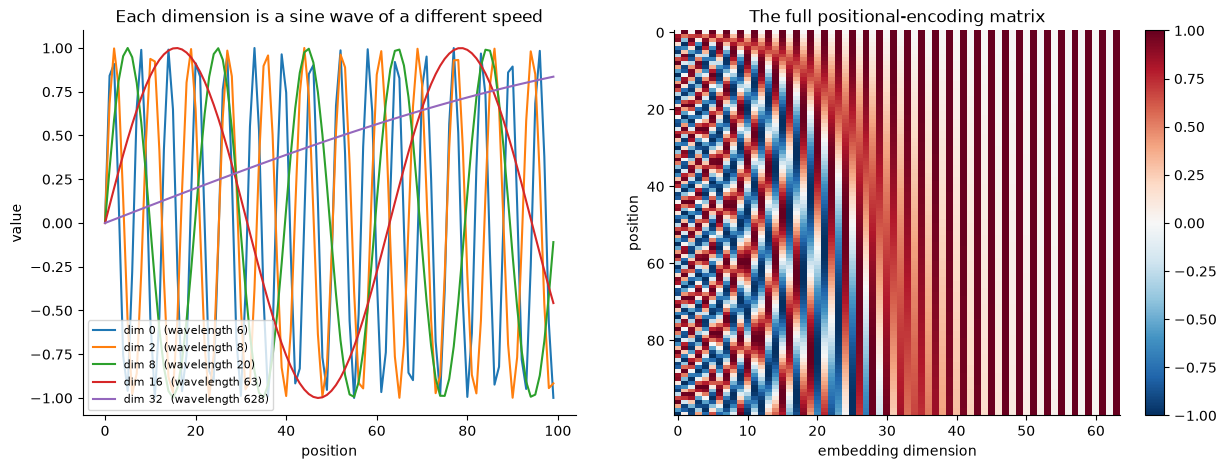

In [3]:
n_pos, d_model = 100, 64
PE = au.sinusoidal_positional_encoding(n_pos, d_model)
print("PE shape:", PE.shape, "| values in", PE.min().round(2), "to", PE.max().round(2))

fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1)
for dim in (0, 2, 8, 16, 32):
    ax1.plot(PE[:, dim], label=f"dim {dim}  (wavelength {2 * np.pi * 10000 ** (dim / d_model):.0f})")
ax1.set_xlabel("position"); ax1.set_ylabel("value"); ax1.set_title("Each dimension is a sine wave of a different speed")
ax1.legend(fontsize=8, loc="lower left")
ax2 = fig.add_subplot(1, 2, 2)
im = ax2.imshow(PE, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax2.set_xlabel("embedding dimension"); ax2.set_ylabel("position"); ax2.set_title("The full positional-encoding matrix")
fig.colorbar(im, ax=ax2, fraction=0.046)
au.save_fig(fig, "08_positional_encoding.png")
plt.show()

## 3. Two useful properties, verified numerically

**(a) Nearby positions look alike.** The dot product $PE_i \cdot PE_j$ is largest when $i = j$ and decays as $|i-j|$ grows, so the encoding carries a sense of *distance*.

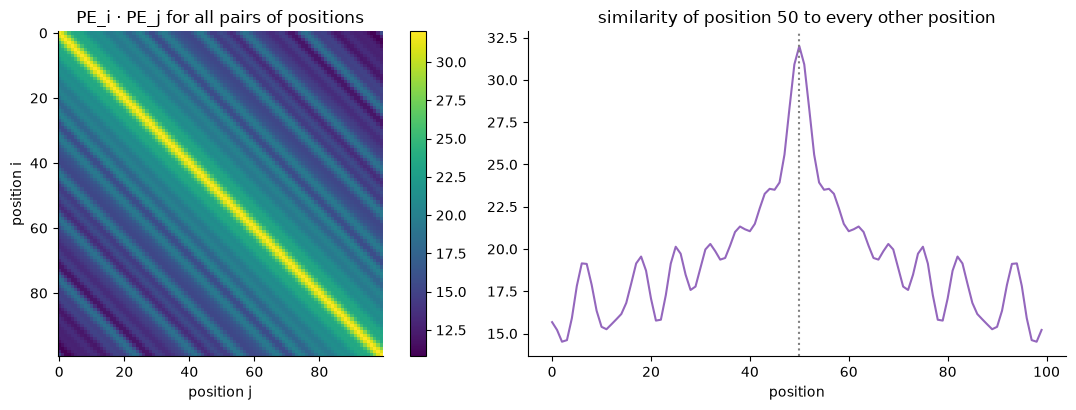

PE_50·PE_50 = 32.0 | PE_50·PE_51 = 30.92 | PE_50·PE_60 = 21.05 | PE_50·PE_90 = 15.4


In [4]:
sim = PE @ PE.T
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
im = axes[0].imshow(sim, cmap="viridis"); axes[0].set_title("PE_i · PE_j for all pairs of positions")
axes[0].set_xlabel("position j"); axes[0].set_ylabel("position i"); fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].plot(sim[50], color="tab:purple"); axes[1].axvline(50, ls=":", color="grey")
axes[1].set_title("similarity of position 50 to every other position"); axes[1].set_xlabel("position")
plt.tight_layout(); plt.show()
print("PE_50·PE_50 =", sim[50, 50].round(2), "| PE_50·PE_51 =", sim[50, 51].round(2), "| PE_50·PE_60 =", sim[50, 60].round(2), "| PE_50·PE_90 =", sim[50, 90].round(2))

**(b) A shift is a rotation.** For any offset $k$ there is a fixed matrix $M_k$ (a rotation in every sine/cosine pair) with $PE_{pos+k} = M_k\,PE_{pos}$ **for every position**. So "three words to the left" is the same linear operation everywhere in the sentence, which makes relative positions easy for attention to learn.

In [5]:
def shift_matrix(k, d_model):
    M = np.zeros((d_model, d_model))
    for i in range(d_model // 2):
        w = 1.0 / 10000 ** (2 * i / d_model)
        c, s = np.cos(w * k), np.sin(w * k)
        # [sin(a+b), cos(a+b)] = [[cos b, sin b], [-sin b, cos b]] @ [sin a, cos a]
        M[2 * i:2 * i + 2, 2 * i:2 * i + 2] = [[c, s], [-s, c]]
    return M

for k in (1, 5, 20):
    M = shift_matrix(k, d_model)
    err = np.abs(PE[k:] - PE[:-k] @ M.T).max()
    print(f"offset {k:2d}: max |PE[pos+{k}] - M_{k} PE[pos]| over all positions = {err:.2e}")

offset  1: max |PE[pos+1] - M_1 PE[pos]| over all positions = 1.12e-14
offset  5: max |PE[pos+5] - M_5 PE[pos]| over all positions = 7.12e-15
offset 20: max |PE[pos+20] - M_20 PE[pos]| over all positions = 7.19e-15


## 4. Adding position breaks the symmetry

Now add the encoding to the word embeddings and rerun the *dog/cat* test. (We scale PE to the size of the embeddings so neither swamps the other.)

In [6]:
PE16 = au.sinusoidal_positional_encoding(3, d) * np.linalg.norm(E, axis=1).mean() / np.sqrt(d / 2)
Z1p = attend(E[[w2i[w] for w in s1]] + PE16)
Z2p = attend(E[[w2i[w] for w in s2]] + PE16)
for w in s1:
    diff = np.abs(Z1p[s1.index(w)] - Z2p[s2.index(w)]).max()
    print(f"'{w}': identical? {np.allclose(Z1p[s1.index(w)], Z2p[s2.index(w)])}  (max difference {diff:.3f})")

'dog': identical? False  (max difference 0.008)
'chases': identical? False  (max difference 0.003)
'cat': identical? False  (max difference 0.007)


The model can now tell *who chased whom*.

## 5. Other ways to encode position

| method | idea | used in |
|--------|------|---------|
| **sinusoidal** (this notebook) | fixed sine/cosine vectors added to embeddings | original Transformer |
| **learned absolute** | a trainable vector per position (`nn.Parameter(L, d)`) — what Notebooks 06 and 07 used | BERT, GPT-2 |
| **relative** | add a learned bias depending on $i-j$ to the attention score | Transformer-XL, T5 |
| **RoPE** (rotary) | rotate each query and key by an angle proportional to its position | LLaMA, many modern LLMs |
| **ALiBi** | subtract a penalty proportional to distance from the score | BLOOM, MPT |

RoPE uses exactly property (b): if queries and keys are rotated by their positions, their dot product depends only on the **relative** offset. Let's verify that in a few lines.

In [7]:
def rope(x, pos):
    """Rotate each consecutive pair of dimensions of x by pos * frequency."""
    d_ = x.shape[-1]
    freqs = 1.0 / 10000 ** (np.arange(0, d_, 2) / d_)
    ang = pos * freqs
    c, s = np.cos(ang), np.sin(ang)
    x1, x2 = x[0::2], x[1::2]
    out = np.empty_like(x)
    out[0::2], out[1::2] = x1 * c - x2 * s, x1 * s + x2 * c
    return out

q, k = rng.normal(size=16), rng.normal(size=16)
for (pq, pk) in [(3, 1), (10, 8), (52, 50)]:
    print(f"query at {pq:2d}, key at {pk:2d} (offset {pq - pk}): score = {rope(q, pq) @ rope(k, pk):.6f}")

query at  3, key at  1 (offset 2): score = -0.084619
query at 10, key at  8 (offset 2): score = -0.084619
query at 52, key at 50 (offset 2): score = -0.084619


Same offset → same score, wherever the pair sits in the sequence.

## Key takeaways

- Self-attention is **permutation-equivariant**: without extra information it cannot tell word order.
- **Positional encodings** inject order; the sinusoidal version uses sine/cosine waves of geometrically spaced frequencies.
- Sinusoidal encodings make **nearby positions similar** and turn **shifts into rotations**; RoPE builds directly on that.

### ✏️ Exercise 1

Plot rows 0, 1 and 50 of `PE` (as functions of the dimension). Why are the right-hand dimensions almost identical for all three positions?

<details>
<summary><b>Show solution</b></summary>

```python
for p in (0, 1, 50):
    plt.plot(PE[p], label=f"pos {p}")
plt.legend(); plt.xlabel("dimension"); plt.show()
```

High dimensions have very long wavelengths, so they barely change over 50 positions.

</details>

### ✏️ Exercise 2

Show that self-attention is permutation-equivariant for a random permutation of 6 random vectors: `attend(X[perm])` should equal `attend(X)[perm]`.

<details>
<summary><b>Show solution</b></summary>

```python
X6 = rng.normal(size=(6, d)); perm = rng.permutation(6)
print(np.allclose(attend(X6[perm]), attend(X6)[perm]))
```



</details>

### ✏️ Exercise 3

Using `rope`, check that the score for offset 2 is different from the score for offset 3 (so RoPE does encode distance).

<details>
<summary><b>Show solution</b></summary>

```python
print(rope(q, 5) @ rope(k, 3), rope(q, 6) @ rope(k, 3))
```



</details>